<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Finding Duplicates in Survey Data: Protecting Data Quality**


**Estimated time needed:** 30 minutes <br>
**Project type:** IBM Skills Network guided data-cleaning lab <br>
**Tools:** Python, pandas, Matplotlib <br>
**Focus:** Identifying exact duplicates, distinguishing repeated responses from duplicate records, and documenting safe cleaning decisions.


### Project overview


Before analyzing survey responses, we need to check whether the same record has been included more than once. Repeated records can inflate totals and distort conclusions. However, **two people giving the same answers does not mean one response is a duplicate.** In this guided lab, I inspect a developer survey dataset, compare common response patterns, and assess when removing rows is justified. The emphasis is on preserving valid participant responses while improving data quality.

### Learning objectives


In this lab, you will perform the following:


By the end of this notebook, readers should understand how to:
1. Identify duplicate rows in the dataset and analyze their characteristics.
2. Visualize the distribution of duplicates based on key attributes.
3. Remove duplicate values strategically based on specific criteria.
4. Outline the process of verifying and documenting duplicate removal.

#### 1. Set up the environment


Install the two libraries used here: pandas for working with tables and Matplotlib for visualizing counts. In a local environment where they are already installed, these commands can be skipped.

In [1]:
!pip install pandas
!pip install matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/10.8 MB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 136.0 MB/s eta 0:00:00

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/16.7 MB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 150.8 MB/s eta 0:00:00


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━

Import pandas module


In [10]:
import pandas as pd

Import matplotlib


In [11]:
import matplotlib as mpl
import matplotlib.pyplot as plt

### 2. Load and inspect the survey dataset

The course supplies a CSV file containing survey responses. Each row represents a record, and each column captures a field such as employment status or remote-work arrangement. The first five rows help verify that the file loaded and reveal its structure. This notebook uses the duplicate-practice CSV consistently for subsequent checks.


In [12]:
# Load the dataset directly from the URL
file_path = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/VYPrOu0Vs3I0hKLLjiPGrA/survey-data-with-duplicate.csv"
df = pd.read_csv(file_path)

# Display the first few rows
print(df.head())

   ResponseId                      MainBranch                 Age  \
0           1  I am a developer by profession  Under 18 years old   
1           2  I am a developer by profession     35-44 years old   
2           3  I am a developer by profession     45-54 years old   
3           4           I am learning to code     18-24 years old   
4           5  I am a developer by profession     18-24 years old   

            Employment RemoteWork   Check  \
0  Employed, full-time     Remote  Apples   
1  Employed, full-time     Remote  Apples   
2  Employed, full-time     Remote  Apples   
3   Student, full-time        NaN  Apples   
4   Student, full-time        NaN  Apples   

                                    CodingActivities  \
0                                              Hobby   
1  Hobby;Contribute to open-source projects;Other...   
2  Hobby;Contribute to open-source projects;Other...   
3                                                NaN   
4                                 

**Reading the preview:** Fields such as ResponseId, MainBranch, Employment, and RemoteWork describe individual survey submissions. A preview confirms the table structure, but it cannot establish whether duplicates exist.

Load the data into a pandas dataframe:



Note: If you are working on a local Jupyter environment, you can use the URL directly in the pandas.read_csv() function as shown below:



In [14]:
df = pd.read_csv("https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv")

### 3. Identify and analyze duplicates


##### Task 1: Check for fully identical rows
df.duplicated() flags a row when its values match an earlier row across all columns. Summing those flags counts the repeated rows. This is stricter than checking whether two people share an employment status or other characteristics.

In [16]:
## Write your code here
No_of_duplicates = df.duplicated().sum()
print("Number of duplicate rows:", No_of_duplicates)

print(df[df.duplicated()].head())

Number of duplicate rows: 0
Empty DataFrame
Columns: [ResponseId, MainBranch, Age, Employment, RemoteWork, Check, CodingActivities, EdLevel, LearnCode, LearnCodeOnline, TechDoc, YearsCode, YearsCodePro, DevType, OrgSize, PurchaseInfluence, BuyNewTool, BuildvsBuy, TechEndorse, Country, Currency, CompTotal, LanguageHaveWorkedWith, LanguageWantToWorkWith, LanguageAdmired, DatabaseHaveWorkedWith, DatabaseWantToWorkWith, DatabaseAdmired, PlatformHaveWorkedWith, PlatformWantToWorkWith, PlatformAdmired, WebframeHaveWorkedWith, WebframeWantToWorkWith, WebframeAdmired, EmbeddedHaveWorkedWith, EmbeddedWantToWorkWith, EmbeddedAdmired, MiscTechHaveWorkedWith, MiscTechWantToWorkWith, MiscTechAdmired, ToolsTechHaveWorkedWith, ToolsTechWantToWorkWith, ToolsTechAdmired, NEWCollabToolsHaveWorkedWith, NEWCollabToolsWantToWorkWith, NEWCollabToolsAdmired, OpSysPersonal use, OpSysProfessional use, OfficeStackAsyncHaveWorkedWith, OfficeStackAsyncWantToWorkWith, OfficeStackAsyncAdmired, OfficeStackSyncHaveWo

**How to interpret the result:** A zero count means no fully identical rows were detected in the active DataFrame. It does not mean that no two people selected the same answers. The saved zero result came from the alternate CSV in the original notebook; rerun to get a valid result for the intended duplicate-practice file.

##### Task 2: Find commonly shared response patterns
Group records by MainBranch, Employment, and RemoteWork to identify combinations that occur frequently. These counts show common answers, not necessarily duplicated respondents. For example, many distinct people can work full-time in hybrid roles.

In [18]:
## Write your code here
selected_columns = ["MainBranch", "Employment", "RemoteWork"]
grouped_columns = (
    df.groupby(selected_columns).size().reset_index(name = "pattern_count")
)

frequent_patterns = grouped_columns.sort_values(by="pattern_count", ascending = False)

print("Frequent identical response:", frequent_patterns.head())

Frequent identical response:                         MainBranch  \
0   I am a developer by profession   
2   I am a developer by profession   
1   I am a developer by profession   
78  I am a developer by profession   
8   I am a developer by profession   

                                           Employment  \
0                                 Employed, full-time   
2                                 Employed, full-time   
1                                 Employed, full-time   
78  Independent contractor, freelancer, or self-em...   
8   Employed, full-time;Independent contractor, fr...   

                              RemoteWork  pattern_count  
0   Hybrid (some remote, some in-person)          15286  
2                                 Remote          12191  
1                              In-person           7118  
78                                Remote           2814  
8                                 Remote           1754  

**Interpretation:** The most common grouped pattern in the saved output occurs 15,286 times for professional developers employed full-time in hybrid roles. This describes a popular combination of answers, not 15,286 duplicate records. As above, the saved result is from the original run on the alternate CSV.

##### Task 3: Visualize employment categories
1. Create visualizations to show the distribution of shared response patterns across different categories.
2. Use bar charts or pie charts to represent the distribution of respondents who share identical values for MainBranch, Employment, and RemoteWork, grouped by Country and Employment.


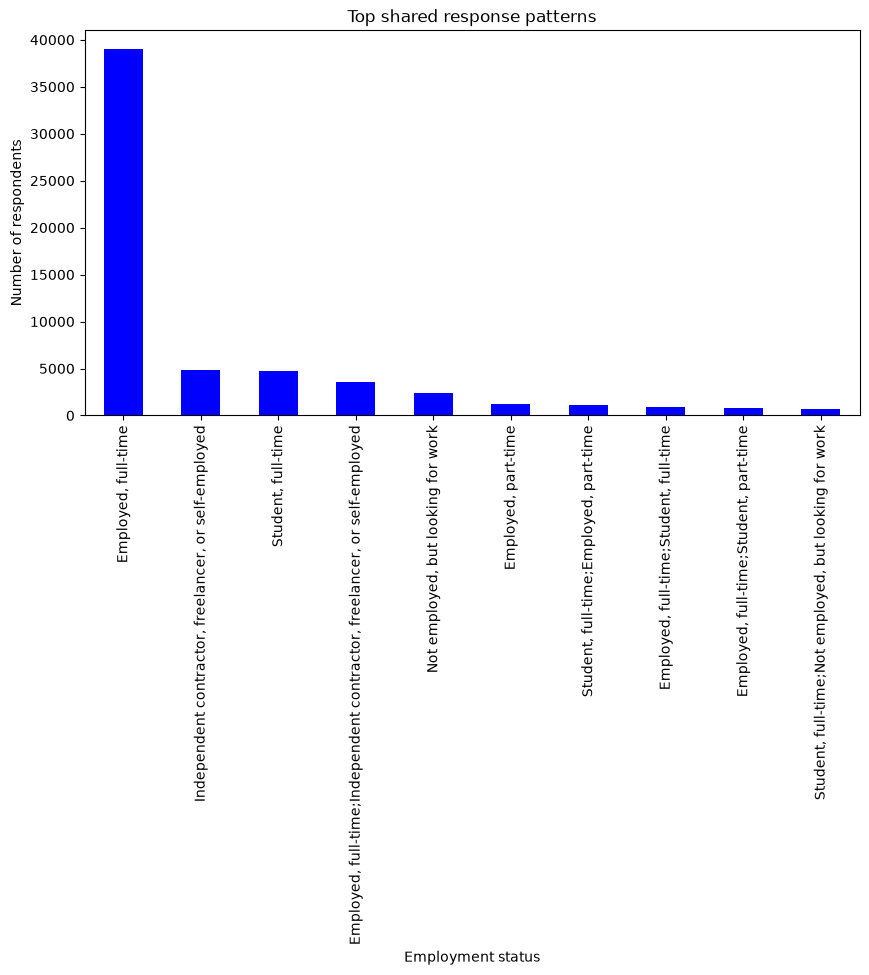

Cleaned dataframe size: (65437, 114)

In [21]:
## Write your code here
top_patterns = df["Employment"].value_counts().head(10)

top_patterns.plot(kind="bar", color="blue", figsize=(10, 5))
plt.title("Top shared response patterns")
plt.ylabel("Number of respondents")
plt.xlabel("Employment status")
plt.show()

#Remove duplicates
df = df.drop_duplicates()
print("Cleaned dataframe size:", df.shape)

**Interpretation:** Taller bars represent more respondents reporting that employment category. The original saved output reports a DataFrame size of 65,437 rows and 114 columns after drop_duplicates(). Because the original run had zero exact duplicates, this operation did not reduce its row count. Rerunning on the practice CSV may produce different numbers.

##### Task 4: Evaluate Duplicate Handling Strategy
1. Analyse the dataset to determine which column(s) define record uniqueness.
2. Assess whether removing rows based on a subset of columns (rather than complete row duplication) is appropriate.
Justify your decision with reference to the structure and purpose of the dataset.


### 4. Verify and document the cleaning decision


##### Task 5: Documentation
1. Document the process of identifying and removing duplicates.


2. Explain the reasoning behind selecting specific columns for identifying and removing duplicates.


### 5. Summary and next steps
In this IBM-guided lab, I used pandas to check exact duplicates, explored repeated response combinations, and visualized employment categories. The key lesson is that common answers are not the same as duplicated records. The saved original run reported zero fully identical rows and a cleaned DataFrame of 65,437 rows * 114 columns, but those outputs were produced after switching to the alternate survey CSV. They should not be treated as results for the duplicate-practice CSV until the revised notebook is rerun.

**Next steps:** Rerun all cells on the intended dataset; compare row counts before and after removal; check whether ResponseId contains nulls or repeated values; and record any exclusions.

**Skills demonstrated:** Data quality assessment, pandas duplicated() and drop_duplicates(), grouped frequency analysis, categorical visualization, and documenting data-cleaning decisions.

**Limitations:** Repeated responses across a few columns do not prove duplication, and removing exact matches alone may not resolve inconsistent records with the same identifier.

**Attribution:** This notebook is adapted from an IBM Skills Network guided lab. Original instructional material and IBM attribution are retained.

<!--
## Change Log
|Date (YYYY-MM-DD)|Version|Changed By|Change Description|
|-|-|-|-|
|2024-11- 05|1.3|Madhusudhan Moole|Updated lab|
|2024-10-28|1.2|Madhusudhan Moole|Updated lab|
|2024-09-24|1.1|Madhusudhan Moole|Updated lab|
|2024-09-23|1.0|Raghul Ramesh|Created lab|
--!>


Copyright © IBM Corporation. All rights reserved.
